# Use Case 15 - Road Safety Insight
**SafeRoute Urban Mobility Lab | Round 2: EDA & Feature Engineering (+ ML model)**

Business question: *Where and when do serious accidents occur and what conditions are commonly associated with them?*

## 1. Load the datasets

In [1]:
import pandas as pd, numpy as np, json, os, warnings
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
os.makedirs('charts', exist_ok=True)

acc = pd.read_csv('accidents.csv')
roads = pd.read_csv('roads.csv')
weather = pd.read_csv('weather.csv')
traffic = pd.read_csv('traffic.csv')
vehicles = pd.read_csv('vehicles.csv')
for n, d in dict(accidents=acc, roads=roads, weather=weather, traffic=traffic, vehicles=vehicles).items():
    print(f'{n:10s} rows={d.shape[0]:5d} cols={d.shape[1]}')

accidents  rows= 6080 cols=6
roads      rows=  120 cols=6
weather    rows= 6000 cols=4
traffic    rows= 6000 cols=3
vehicles   rows= 6000 cols=3


## 2. Check data types, missing values, duplicates and unusual values

In [2]:
for n, d in dict(accidents=acc, roads=roads, weather=weather, traffic=traffic, vehicles=vehicles).items():
    print('=====', n, '=====')
    print(d.dtypes.to_string())
    print('Missing:', d.isna().sum()[d.isna().sum() > 0].to_dict())
    print('Duplicate rows:', d.duplicated().sum())
    print()
print('Duplicate accident_id in accidents:', acc['accident_id'].duplicated().sum())
print('Severity values:', acc['severity'].value_counts(dropna=False).to_dict())
print('Road type values:', sorted(roads['road_type'].unique()))
print(weather[['visibility_km','rain_mm']].describe().round(2))
print(traffic['traffic_volume'].describe().round(1))

===== accidents =====
accident_id        str
road_id            str
date_time          str
severity           str
latitude       float64
longitude      float64
Missing: {'severity': 12, 'latitude': 153, 'longitude': 154}
Duplicate rows: 76

===== roads =====
road_id            str
road_type          str
speed_limit      int64
junction           str
latitude       float64
longitude      float64
Missing: {}
Duplicate rows: 0

===== weather =====
accident_id          str
condition            str
visibility_km    float64
rain_mm          float64
Missing: {'condition': 120, 'visibility_km': 250, 'rain_mm': 250}
Duplicate rows: 0

===== traffic =====
accident_id         str
traffic_volume    int64
peak_flag         int64
Missing: {}
Duplicate rows: 0

===== vehicles =====
accident_id           str
vehicle_category      str
vehicle_count       int64
Missing: {}
Duplicate rows: 0

Duplicate accident_id in accidents: 80
Severity values: {'Serious': 2718, 'Minor': 1948, 'Fatal': 1354, 'SERIOUS':

## 3. Clean the data

In [3]:
issues = {}
# 3.1 duplicate incident IDs
issues['duplicate_incident_rows_removed'] = int(acc['accident_id'].duplicated().sum())
acc = acc.drop_duplicates(subset='accident_id', keep='first').copy()

# 3.2 invalid / inconsistent severity values
acc['severity'] = acc['severity'].astype(str).str.strip().str.title()
valid = ['Minor', 'Serious', 'Fatal']
issues['invalid_severity_rows_removed'] = int((~acc['severity'].isin(valid)).sum())
acc = acc[acc['severity'].isin(valid)].copy()

# 3.3 inconsistent road labels
def fix_road(x):
    x = str(x).strip().lower()
    if x in ('highway', 'hwy'): return 'Highway'
    if x in ('local', 'local rd'): return 'Local'
    return x.title()
roads['road_type'] = roads['road_type'].apply(fix_road)
print('Road types now:', sorted(roads['road_type'].unique()))

# 3.4 missing locations -> fill from the road's own coordinates
issues['missing_location_rows'] = int(acc[['latitude','longitude']].isna().any(axis=1).sum())
rc = roads.set_index('road_id')[['latitude','longitude']]
for c in ['latitude','longitude']:
    acc[c] = acc[c].fillna(acc['road_id'].map(rc[c]))

# 3.5 missing weather observations
issues['missing_weather_condition'] = int(weather['condition'].isna().sum())
issues['missing_visibility'] = int(weather['visibility_km'].isna().sum())
issues['missing_rain'] = int(weather['rain_mm'].isna().sum())
weather['condition'] = weather['condition'].fillna('Unknown')
# outliers: rain above 100 mm per event is implausible -> cap at 100
issues['rain_outliers_capped'] = int((weather['rain_mm'] > 100).sum())
weather['rain_mm'] = weather['rain_mm'].clip(upper=100)
for c in ['visibility_km', 'rain_mm']:
    weather[c] = weather[c].fillna(weather.groupby('condition')[c].transform('median'))
    weather[c] = weather[c].fillna(weather[c].median())

# 3.6 traffic outliers: IQR capping
q1, q3 = traffic['traffic_volume'].quantile([.25, .75]); hi = q3 + 1.5 * (q3 - q1)
issues['traffic_outliers_capped'] = int((traffic['traffic_volume'] > hi).sum())
traffic['traffic_volume'] = traffic['traffic_volume'].clip(upper=hi)
print(json.dumps(issues, indent=2))

Road types now: ['Arterial', 'Collector', 'Expressway', 'Highway', 'Local']
{
  "duplicate_incident_rows_removed": 80,
  "invalid_severity_rows_removed": 35,
  "missing_location_rows": 293,
  "missing_weather_condition": 120,
  "missing_visibility": 250,
  "missing_rain": 250,
  "rain_outliers_capped": 6,
  "traffic_outliers_capped": 8
}


## 4. Combine into one analysis table

In [4]:
df = (acc.merge(roads.drop(columns=['latitude','longitude']), on='road_id', how='left')
         .merge(weather, on='accident_id', how='left')
         .merge(traffic, on='accident_id', how='left')
         .merge(vehicles, on='accident_id', how='left'))
df['date_time'] = pd.to_datetime(df['date_time'])
print(df.shape); print('Remaining missing:', int(df.isna().sum().sum()))
df.head()

(5965, 16)
Remaining missing: 0


,accident_id,road_id,date_time,severity,latitude,longitude,road_type,speed_limit,junction,condition,visibility_km,rain_mm,traffic_volume,peak_flag,vehicle_category,vehicle_count
0,A00369,R088,2025-05-21 15:40:00,Minor,13.11416,80.24678,Arterial,50,Yes,Clear,6.73,0.0,632,0,Car,1
1,A03668,R101,2025-07-17 14:23:00,Serious,13.01262,80.16987,Expressway,100,Yes,Cloudy,10.22,0.0,1075,0,Auto-rickshaw,2
2,A02140,R096,2025-03-20 07:09:00,Fatal,12.93780,80.12541,Collector,60,Yes,Storm,1.05,59.8,2273,1,Motorcycle,3
3,A05483,R073,2024-05-11 15:47:00,Minor,12.99237,80.20917,Local,20,No,Cloudy,11.90,0.0,1123,0,Motorcycle,2
4,A01095,R104,2024-03-18 05:50:00,Serious,13.00321,80.18213,Expressway,100,Yes,Rain,3.37,15.5,1052,0,Auto-rickshaw,2


## 5. Feature engineering

In [5]:
df['hour'] = df['date_time'].dt.hour
df['weekday'] = df['date_time'].dt.day_name()
df['month'] = df['date_time'].dt.month
df['is_weekend'] = df['date_time'].dt.dayofweek.isin([5, 6]).astype(int)
df['time_band'] = pd.cut(df['hour'], [-1, 5, 11, 16, 21, 23],
                         labels=['Night', 'Morning', 'Afternoon', 'Evening', 'Late Night'])
df['time_band'] = df['time_band'].replace({'Late Night': 'Night'}).astype(str)
df['is_night'] = ((df['hour'] >= 22) | (df['hour'] <= 4)).astype(int)
df['low_visibility'] = (df['visibility_km'] < 2).astype(int)
df['is_raining'] = (df['rain_mm'] > 0).astype(int)
df['is_junction'] = (df['junction'] == 'Yes').astype(int)
# recurring-incident features (per road)
df['road_incident_count'] = df.groupby('road_id')['accident_id'].transform('count')
df['is_hotspot_road'] = (df['road_incident_count'] >= df['road_incident_count'].quantile(0.85)).astype(int)
df['severe'] = df['severity'].isin(['Serious', 'Fatal']).astype(int)
print(df[['hour','time_band','is_night','low_visibility','is_raining','road_incident_count','is_hotspot_road']].head())
print('\nSeverity distribution:\n', df['severity'].value_counts())

   hour  time_band  is_night  low_visibility  is_raining  road_incident_count  \
0    15  Afternoon         0               0           0                   43   
1    14  Afternoon         0               0           0                   39   
2     7    Morning         0               1           1                  149   
3    15  Afternoon         0               0           0                   58   
4     5      Night         0               0           1                   40   

   is_hotspot_road  
0                0  
1                0  
2                0  
3                0  
4                0  

Severity distribution:
 severity
Serious    2699
Minor      1925
Fatal      1341
Name: count, dtype: int64


## 6. Descriptive analysis and visualizations (answers to the use-case questions)

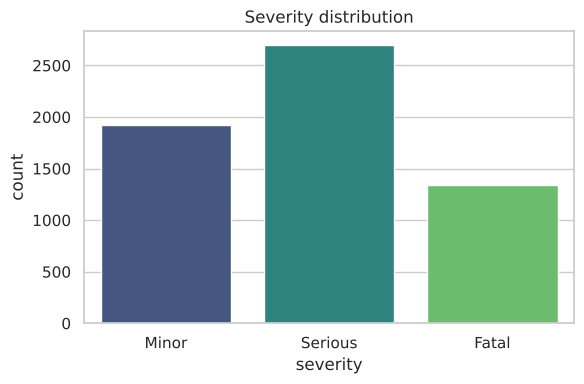

         total  severe  severe_rate
road_id                            
R050       172     172         1.00
R032       168     161         0.96
R096       149     144         0.97
R097       145     144         0.99
R037       142     141         0.99
R068       171     139         0.81
R090       147     137         0.93
R045       158     130         0.82
R017       158     120         0.76
R087       161     114         0.71


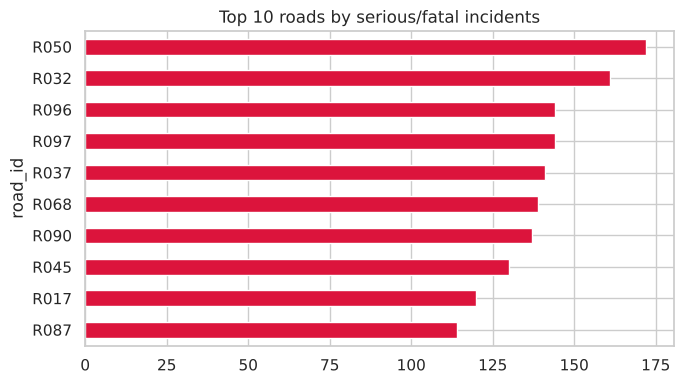

In [6]:
order = ['Minor', 'Serious', 'Fatal']
fig, ax = plt.subplots(figsize=(6,4))
sns.countplot(data=df, x='severity', order=order, palette='viridis', ax=ax)
ax.set_title('Severity distribution'); plt.tight_layout(); plt.savefig('charts/01_severity.png', dpi=130); plt.show()

# Q1 Which locations have more severe accidents?
top = (df.groupby('road_id').agg(total=('accident_id','count'), severe=('severe','sum')).assign(severe_rate=lambda x: x.severe/x.total)
         .sort_values('severe', ascending=False).head(10))
print(top.round(2))
top['severe'].plot(kind='barh', figsize=(7,4), color='crimson', title='Top 10 roads by serious/fatal incidents').invert_yaxis()
plt.tight_layout(); plt.savefig('charts/02_top_roads.png', dpi=130); plt.show()

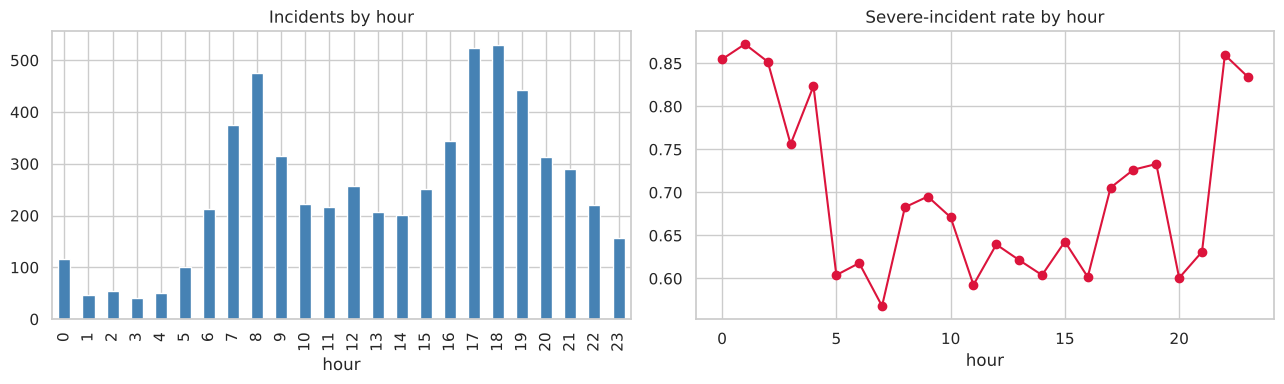

weekday
Monday       911
Friday       872
Wednesday    868
Saturday     845
Tuesday      833
Sunday       826
Thursday     810
dtype: int64
time_band
Afternoon    0.621
Evening      0.691
Morning      0.642
Night        0.814
Name: severe, dtype: float64


In [7]:
# Q2 Which times show higher incident counts?
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df.groupby('hour').size().plot(kind='bar', ax=axes[0], color='steelblue', title='Incidents by hour')
df.groupby('hour')['severe'].mean().plot(kind='line', marker='o', ax=axes[1], color='crimson', title='Severe-incident rate by hour')
plt.tight_layout(); plt.savefig('charts/03_hour.png', dpi=130); plt.show()
print(df.groupby('weekday').size().sort_values(ascending=False))
print(df.groupby('time_band')['severe'].mean().round(3))

severity   Minor  Serious  Fatal
condition                       
Clear      0.378    0.440  0.182
Cloudy     0.389    0.439  0.171
Fog        0.104    0.492  0.404
Rain       0.258    0.469  0.273
Storm      0.144    0.531  0.325
Unknown    0.358    0.350  0.292


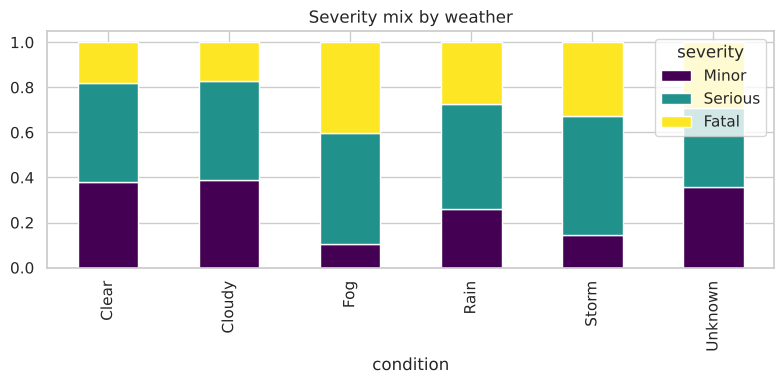

severity  Minor  Serious  Fatal
junction                       
No        0.450    0.411  0.139
Yes       0.179    0.499  0.321
            incidents  severe_rate
road_type                         
Arterial         1692        0.696
Local            1520        0.410
Collector        1169        0.683
Highway          1151        0.903
Expressway        433        0.931


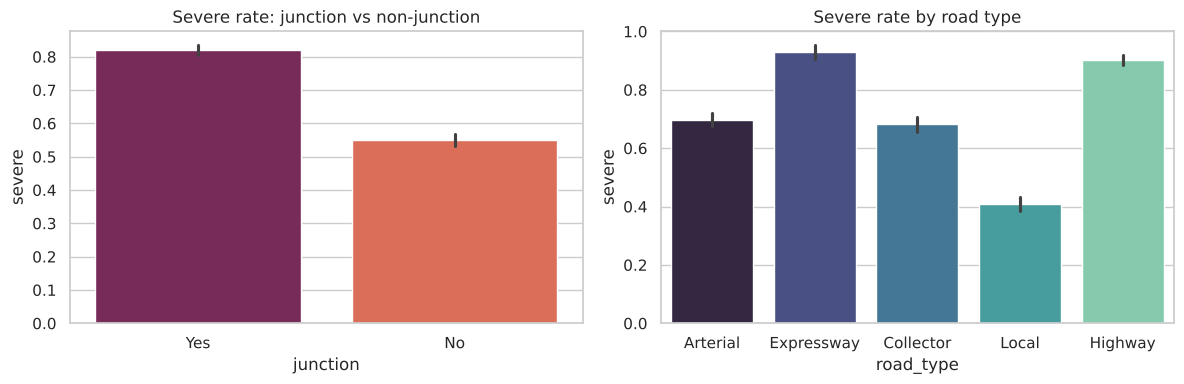

In [8]:
# Q3 How does weather relate to severity?
ct = pd.crosstab(df['condition'], df['severity'], normalize='index')[order].round(3)
print(ct)
ct.plot(kind='bar', stacked=True, figsize=(8,4), colormap='viridis', title='Severity mix by weather')
plt.tight_layout(); plt.savefig('charts/04_weather.png', dpi=130); plt.show()

# Q4 Junction vs non-junction
print(pd.crosstab(df['junction'], df['severity'], normalize='index')[order].round(3))
# Q5 Road types with recurring incidents
rt = df.groupby('road_type').agg(incidents=('accident_id','count'), severe_rate=('severe','mean')).round(3).sort_values('incidents', ascending=False)
print(rt)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=df.reset_index(), x='junction', y='severe', ax=axes[0], palette='rocket'); axes[0].set_title('Severe rate: junction vs non-junction')
sns.barplot(data=df.reset_index(), x='road_type', y='severe', ax=axes[1], palette='mako'); axes[1].set_title('Severe rate by road type')
plt.tight_layout(); plt.savefig('charts/05_junction_roadtype.png', dpi=130); plt.show()

           incidents  severe_rate  avg_volume
peak_flag                                    
0               3304        0.667     764.403
1               2661        0.690    1810.014


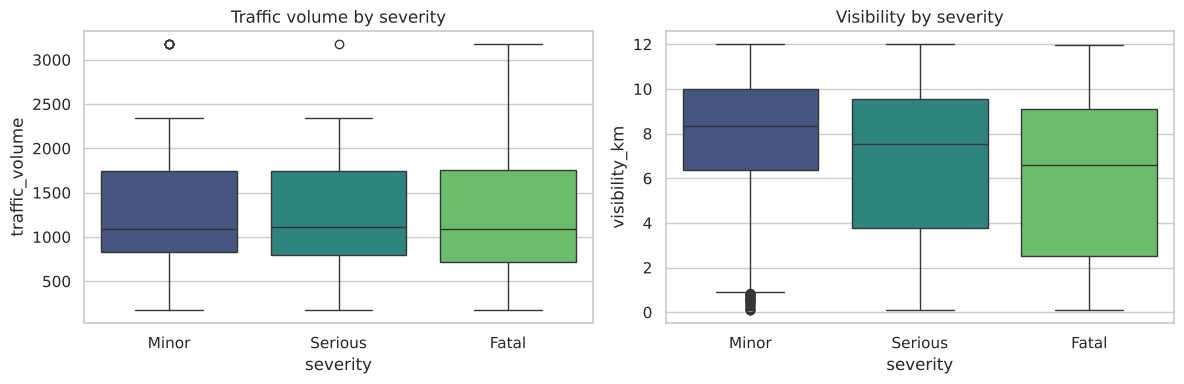

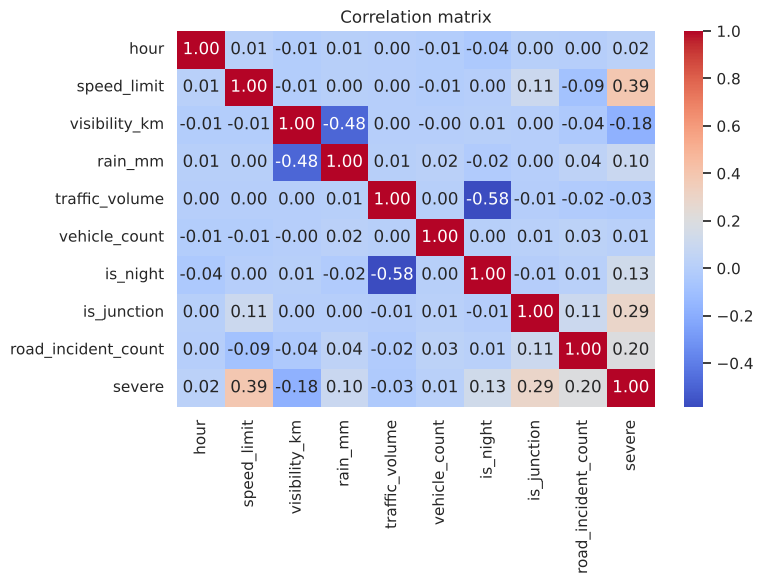

In [9]:
# Q6 Traffic volume vs accidents
print(df.groupby('peak_flag').agg(incidents=('accident_id','count'), severe_rate=('severe','mean'), avg_volume=('traffic_volume','mean')).round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x='severity', y='traffic_volume', order=order, ax=axes[0], palette='viridis'); axes[0].set_title('Traffic volume by severity')
sns.boxplot(data=df, x='severity', y='visibility_km', order=order, ax=axes[1], palette='viridis'); axes[1].set_title('Visibility by severity')
plt.tight_layout(); plt.savefig('charts/06_traffic_visibility.png', dpi=130); plt.show()

# Correlation heatmap
num = ['hour','speed_limit','visibility_km','rain_mm','traffic_volume','vehicle_count','is_night','is_junction','road_incident_count','severe']
plt.figure(figsize=(8,6)); sns.heatmap(df[num].corr(), annot=True, fmt='.2f', cmap='coolwarm'); plt.title('Correlation matrix')
plt.tight_layout(); plt.savefig('charts/07_correlation.png', dpi=130); plt.show()

## 7. Encode categorical variables and select features

Encoded feature matrix: (5965, 42)


visibility_km                  0.110
traffic_volume                 0.108
road_incident_count            0.081
month                          0.075
speed_limit                    0.071
hour                           0.067
vehicle_count                  0.040
is_junction                    0.037
rain_mm                        0.030
road_type_Local                0.027
vehicle_category_Car           0.019
vehicle_category_Motorcycle    0.018
dtype: float64


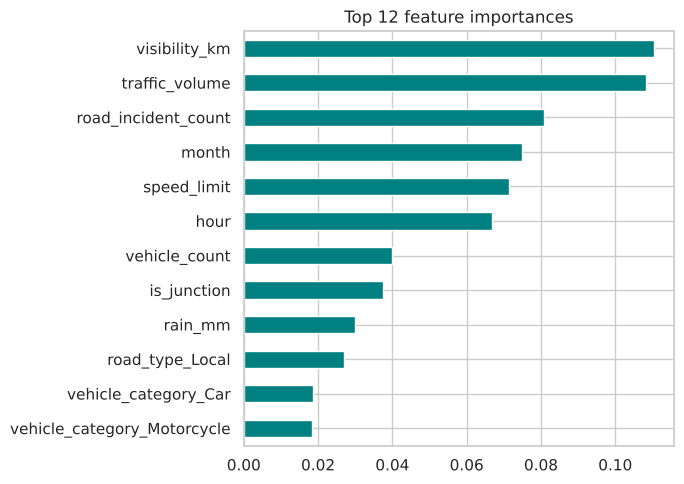

PCA: 27 components explain 95% variance (of 42) - feature selection used instead for interpretability


In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

cat_cols = ['road_type', 'condition', 'time_band', 'vehicle_category', 'weekday']
feature_cols = ['hour','month','is_weekend','is_night','speed_limit','is_junction','visibility_km','rain_mm',
                'low_visibility','traffic_volume','peak_flag','vehicle_count','road_incident_count','is_hotspot_road']
X = pd.get_dummies(df[feature_cols + cat_cols], columns=cat_cols, drop_first=False).astype(float)
y = df['severity']
print('Encoded feature matrix:', X.shape)

rf_sel = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1).fit(X, y)
imp = pd.Series(rf_sel.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp.head(12).round(3))
imp.head(12).sort_values().plot(kind='barh', figsize=(7,5), title='Top 12 feature importances', color='teal')
plt.tight_layout(); plt.savefig('charts/08_feature_importance.png', dpi=130); plt.show()

selected = imp.head(15).index.tolist()
pca = PCA().fit(StandardScaler().fit_transform(X))
n95 = int(np.argmax(np.cumsum(pca.explained_variance_ratio_) >= 0.95) + 1)
print(f'PCA: {n95} components explain 95% variance (of {X.shape[1]}) - feature selection used instead for interpretability')

## 8. Baseline machine-learning model (predict severity)

Logistic Regression {'accuracy': 0.5432, 'f1_weighted': 0.5349, 'f1_macro': 0.5426}


Random Forest {'accuracy': 0.539, 'f1_weighted': 0.536, 'f1_macro': 0.5381}

               precision    recall  f1-score   support

       Fatal       0.42      0.54      0.47       268
       Minor       0.64      0.70      0.67       385
     Serious       0.54      0.42      0.47       540

    accuracy                           0.54      1193
   macro avg       0.53      0.56      0.54      1193
weighted avg       0.54      0.54      0.54      1193



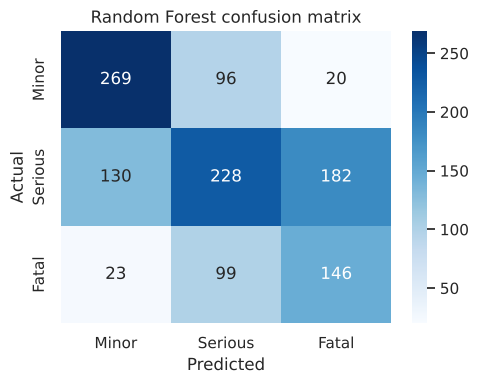

5-fold weighted F1: 0.5408 +/- 0.0053


In [11]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

Xs = X[selected]
Xtr, Xte, ytr, yte = train_test_split(Xs, y, test_size=0.2, stratify=y, random_state=42)

models = {
  'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced'),
  'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_leaf=3, class_weight='balanced', random_state=42, n_jobs=-1),
}
results = {}
for name, m in models.items():
    if name == 'Logistic Regression':
        sc = StandardScaler().fit(Xtr); m.fit(sc.transform(Xtr), ytr); pred = m.predict(sc.transform(Xte))
    else:
        m.fit(Xtr, ytr); pred = m.predict(Xte)
    results[name] = dict(accuracy=round(accuracy_score(yte, pred), 4), f1_weighted=round(f1_score(yte, pred, average='weighted'), 4), f1_macro=round(f1_score(yte, pred, average='macro'), 4))
    print(name, results[name])

best = 'Random Forest'
pred = models[best].predict(Xte)
print('\n', classification_report(yte, pred))
cm = confusion_matrix(yte, pred, labels=order)
plt.figure(figsize=(5,4)); sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=order, yticklabels=order)
plt.title('Random Forest confusion matrix'); plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.tight_layout(); plt.savefig('charts/09_confusion.png', dpi=130); plt.show()
cv = cross_val_score(models[best], Xs, y, cv=5, scoring='f1_weighted')
print('5-fold weighted F1:', cv.mean().round(4), '+/-', cv.std().round(4))

## 9. Save outputs

In [12]:
df.to_csv('cleaned_road_safety.csv', index=False)
summary = dict(
    rows_final=int(len(df)), columns_final=int(df.shape[1]), issues=issues,
    models=results, cv_f1_weighted=round(float(cv.mean()), 4),
    selected_features=selected,
    top_roads=top.head(5).index.tolist(),
    severe_rate_junction=df.groupby('junction')['severe'].mean().round(3).to_dict(),
    severe_rate_weather=df.groupby('condition')['severe'].mean().round(3).to_dict(),
    severe_rate_timeband=df.groupby('time_band')['severe'].mean().round(3).to_dict(),
    severe_rate_roadtype=df.groupby('road_type')['severe'].mean().round(3).to_dict(),
    peak_hours=df.groupby('hour').size().sort_values(ascending=False).head(4).index.tolist(),
    severity_counts=df['severity'].value_counts().to_dict(),
)
json.dump(summary, open('summary.json', 'w'), indent=2, default=str)
print(json.dumps(summary, indent=2, default=str))

{
  "rows_final": 5965,
  "columns_final": 28,
  "issues": {
    "duplicate_incident_rows_removed": 80,
    "invalid_severity_rows_removed": 35,
    "missing_location_rows": 293,
    "missing_weather_condition": 120,
    "missing_visibility": 250,
    "missing_rain": 250,
    "rain_outliers_capped": 6,
    "traffic_outliers_capped": 8
  },
  "models": {
    "Logistic Regression": {
      "accuracy": 0.5432,
      "f1_weighted": 0.5349,
      "f1_macro": 0.5426
    },
    "Random Forest": {
      "accuracy": 0.539,
      "f1_weighted": 0.536,
      "f1_macro": 0.5381
    }
  },
  "cv_f1_weighted": 0.5408,
  "selected_features": [
    "visibility_km",
    "traffic_volume",
    "road_incident_count",
    "month",
    "speed_limit",
    "hour",
    "vehicle_count",
    "is_junction",
    "rain_mm",
    "road_type_Local",
    "vehicle_category_Car",
    "vehicle_category_Motorcycle",
    "weekday_Monday",
    "is_weekend",
    "road_type_Highway"
  ],
  "top_roads": [
    "R050",
    "R032"